# Microproyecto 04
## Clasificación de Sonidos de la Naturaleza con Audio Spectrogram Transformer (AST)

**Materia:** Técnicas de Deep Learning  
**Programa:** Maestría en IA  
**Estudiantes:** Sergio Pardo, Jefferson Moreno, John Pino  
**Fecha:** Mayo 2026  
**Universidad de los Andes**

---


### 1. Introducción y Contexto Técnico

El presente trabajo aborda la clasificación de sonidos ambientales utilizando la arquitectura Audio Spectrogram Transformer (AST) [1]. A diferencia de los enfoques convencionales que emplean Redes Neuronales Convolucionales (CNN) sobre espectrogramas, el AST aplica un mecanismo de atención pura sobre parches de audio, permitiendo capturar relaciones de largo alcance tanto en el dominio del tiempo como de la frecuencia [1].

Para este desarrollo, utilizaremos el dataset ESC-50 (Environmental Sound Classification), el cual es un estándar en la industria para evaluar modelos de reconocimiento de audio ambiental [2]. Nos enfocaremos específicamente en sonidos de la naturaleza, integrando el ecosistema de Hugging Face para la implementación del pipeline [3].

### 2. Preparación del Entorno y Carga del Dataset

Se empieza configurando el entorno de ejecución. Es necesario asegurar el uso de aceleración por hardware (GPU) debido a la complejidad computacional de los modelos basados en Transformers, de lo contrario el procesamiento sería más demorado al usar la CPU.

Posteriormente, procederemos con la carga del dataset ESC-50. Este dataset es una colección etiquetada de 2,000 grabaciones ambientales de 5 segundos de duración, organizadas en 50 clases semánticas [2].

In [32]:
# IMPORTACIÓN DE LIBRERÍAS

import torch
import torchaudio
import torch.nn as nn
import numpy as np
import pandas as pd
from datasets import load_dataset
from transformers import ASTForAudioClassification, ASTFeatureExtractor, Trainer, TrainingArguments
import hashlib
import matplotlib.pyplot as plt
import seaborn as sns
import IPython.display as ipd
import evaluate
from sklearn.metrics import confusion_matrix, classification_report


In [2]:
# Verificación y configuración de hardware según estándares de PyTorch
if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Dispositivo detectado: Apple Silicon GPU (MPS)")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print("Dispositivo detectado: NVIDIA GPU (CUDA)")
else:
    device = torch.device("cpu")
    print("No se detectó aceleración por hardware. Usando CPU.")


Dispositivo detectado: Apple Silicon GPU (MPS)


In [3]:
# Carga del dataset ESC-50 (Fold 1) [2]
# Este conjunto contiene grabaciones de 5 segundos a 44.1 kHz.
# Se descargará un dataset de entrenamiento y otro de prueba
print("Cargando dataset ESC-50 desde el hub de Hugging Face...")
dataset = load_dataset("confit/esc50-demo", "fold1", split="train")
val_dataset = load_dataset("confit/esc50-demo", "fold1", split="test")

print(f"Ejemplos de entrenamiento: {len(dataset)}")
print(f"Ejemplos de validación: {len(val_dataset)}")

Cargando dataset ESC-50 desde el hub de Hugging Face...


Ejemplos de entrenamiento: 1600
Ejemplos de validación: 400


In [4]:
dataset

Dataset({
    features: ['audio', 'sound', 'label'],
    num_rows: 1600
})

___
#### 3. Exploración y Limpieza del Dataset

Antes de proceder con el entrenamiento, se realiza un Análisis Exploratorio de Datos (EDA) para identificar posibles anomalías. Se procede también con la limpieza del dataset verificando campos vacíos o columnas irrelevantes, eliminación de duplicados mediante comparación del HASH de cada muestra y revisando la validez de los datos en cuanto a duración y frecuencia de muestreo esperadas

El hashing digital genera una huella única para cada señal de audio, permitiendo detectar duplicados exactos en el dataset ESC-50 [2] que los metadatos podrían omitir. Este control de integridad es fundamental para prevenir el data leakage (filtración de datos), garantizando que el modelo AST [1] y su arquitectura Transformer [3] logren generalizar los patrones acústicos de la naturaleza en lugar de memorizar muestras idénticas.

In [5]:
# Detección de duplicados por hashing de cada muestra

def check_dataset(ds, name="Dataset"):
    print(f"\nRevisión del Dataset: {name}")
    
    # Se verifican Valores Nulos en los Metadatos
    # Se elimina la columna audio en el dataframe df_meta
    df_meta = pd.DataFrame(ds.remove_columns(["audio"]))
    null_counts = df_meta.isnull().sum().sum()
    print(f"Valores nulos en metadatos: {null_counts}")
    
    # Detección de Duplicados por Huella Digital (Audio Hashing)
    # Se genera un hash SHA-256 para cada arreglo de audio
    print("Generando huellas digitales de los audios...")
    
    def generate_audio_hash(example):
        # Se convierte el arreglo de audio a bytes para generar el hash
        audio_bytes = example["audio"]["array"].tobytes()
        return {"audio_hash": hashlib.sha256(audio_bytes).hexdigest()}
    
    # Se aplica la función para crear una columna temporal de hashes
    ds_with_hashes = ds.map(generate_audio_hash, batched=False)
    
    # Se cuentan los duplicados en la columna de hashes
    hash_list = ds_with_hashes["audio_hash"]
    duplicate_count = len(hash_list) - len(set(hash_list))
    
    print(f"Muestras con audio idéntico detectadas: {duplicate_count}")
    
    if duplicate_count > 0:
        print("Audios repetidos:",duplicate_count)
    else:
        print("No se detectaron duplicados.")
        
    return ds_with_hashes

# Se ejecuta la revisión
train_checked = check_dataset(dataset, "Entrenamiento")
val_checked = check_dataset(val_dataset, "Validación")


Revisión del Dataset: Entrenamiento
Valores nulos en metadatos: 0
Generando huellas digitales de los audios...
Muestras con audio idéntico detectadas: 0
No se detectaron duplicados.

Revisión del Dataset: Validación
Valores nulos en metadatos: 0
Generando huellas digitales de los audios...
Muestras con audio idéntico detectadas: 0
No se detectaron duplicados.


**De lo anterior se observa que no existen datos nulos ni datos duplicados en ninguno de los 2 datasets a utilizar.**

#### 3.1 Análisis de Clases Únicas
Se debe identificar con exactitud qué etiquetas de texto contiene la columna sound. Esto nos permite construir un diccionario de mapeo preciso y evitar errores por diferencias de escritura o categorías inesperadas en la versión demo del dataset ESC-50 [2].

In [6]:
# Se obtienen las clases únicas presentes en el set de entrenamiento y validación
clases_entrenamiento = set(dataset['sound'])
clases_validacion = set(val_dataset['sound'])

print(f"Total de clases únicas encontradas: {len(clases_entrenamiento)}")

# Se verifica si ambos sets tienen las mismas clases (consistencia)
if clases_entrenamiento == clases_validacion:
    print("Consistencia verificada: Ambos sets contienen las mismas categorías.")
else:
    print("Advertencia: Hay discrepancias entre las clases de entrenamiento y validación.")

Total de clases únicas encontradas: 50
Consistencia verificada: Ambos sets contienen las mismas categorías.


Ya que se tienen 50 clases únicas y el proyecto pide 4 clases principales: aves, viento, agua y mamíferos, se procede a realizar la agrupación manual de las clases.


In [7]:
# Se revisan las 50 clases de entrenamiento
clases_entrenamiento

{'airplane',
 'breathing',
 'brushing_teeth',
 'can_opening',
 'car_horn',
 'cat',
 'chainsaw',
 'chirping_birds',
 'church_bells',
 'clapping',
 'clock_alarm',
 'clock_tick',
 'coughing',
 'cow',
 'crackling_fire',
 'crickets',
 'crow',
 'crying_baby',
 'dog',
 'door_wood_creaks',
 'door_wood_knock',
 'drinking_sipping',
 'engine',
 'fireworks',
 'footsteps',
 'frog',
 'glass_breaking',
 'hand_saw',
 'helicopter',
 'hen',
 'insects',
 'keyboard_typing',
 'laughing',
 'mouse_click',
 'pig',
 'pouring_water',
 'rain',
 'rooster',
 'sea_waves',
 'sheep',
 'siren',
 'sneezing',
 'snoring',
 'thunderstorm',
 'toilet_flush',
 'train',
 'vacuum_cleaner',
 'washing_machine',
 'water_drops',
 'wind'}

Con la lista completa de las 50 clases, se puede realizar una Mapeo Taxonómico preciso. Esta es una fase crítica donde se aplica el conocimiento de dominio para consolidar etiquetas específicas en las categorías requeridas por el microproyecto.

A diferencia de un filtrado automático, esta división manual permite agrupar sonidos que comparten texturas acústicas similares (por ejemplo, todas las variantes de animales mamíferos o fenómenos hídricos), lo que facilita el aprendizaje de características de alto nivel por parte del AST [1].

#### 3.2 Mapeo Taxonómico y Consolidación de Etiquetas

Se ha seleccionado de la lista de 50 clases aquellas que representan fielmente las categorías de Aves, Agua, Viento y Mamíferos. Los sonidos mecánicos (como airplane o chainsaw) y los sonidos humanos (como sneezing o clapping) serán excluidos para especializar el modelo

**Grupos Seleccionados:**
- Aves (4): chirping_birds, crow, rooster, hen.
- Agua (4): pouring_water, rain, sea_waves, water_drops.
- Viento (2): wind, thunderstorm
- Mamíferos (5): cat, cow, dog, pig, sheep.

In [8]:
# Mapeo semántico 
# Diccionario de mapeo basado en la inspección de las 50 clases
nature_map = {
    # 0. AVES
    "chirping_birds": 0, "crow": 0, "rooster": 0, "hen": 0, 
    
    # 1. AGUA
    "rain": 1, "sea_waves": 1, "water_drops": 1, "pouring_water": 1,
    
    # 2. VIENTO
    "wind": 2, "thunderstorm": 2,
    
    # 3. MAMÍFEROS
    "dog": 3, "cat": 3, "pig": 3, "cow": 3, "sheep": 3
}


In [9]:
# Se define una función para asignar el nuevo índice de etiqueta
def filter_and_label(example):
    sound_name = example["sound"]
    
    if sound_name in nature_map:
        # Se asigna el nuevo ID (0-3) en una columna 'label'
        example["label"] = nature_map[sound_name]
        return True
    return False

In [10]:
# Se aplica el filtro a los datasets originales cargados anteriormente
train = dataset.filter(filter_and_label)
val = val_dataset.filter(filter_and_label)

print(f"Mapeo completado.")
print(f"Muestras totales de Entrenamiento: {len(train)}")
print(f"Muestras totales de Validación: {len(val)}")

Mapeo completado.
Muestras totales de Entrenamiento: 480
Muestras totales de Validación: 120


#### 3.3 Revisión del balance de clases

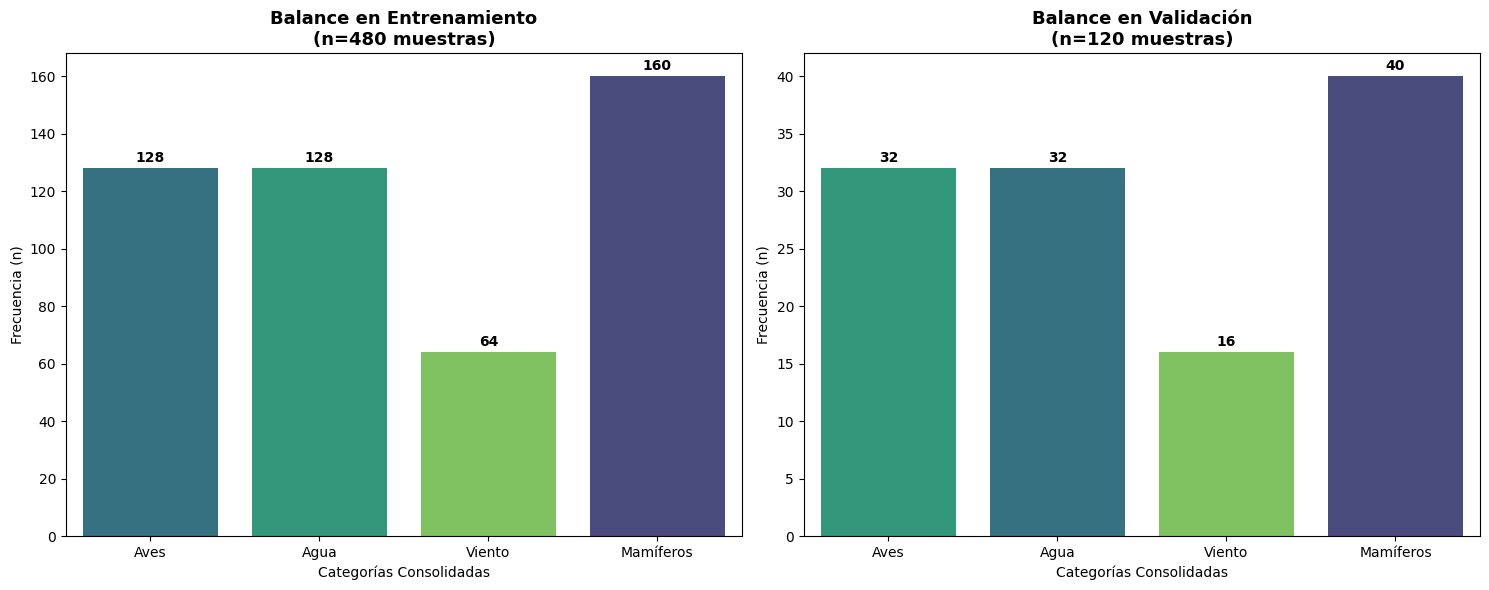

In [11]:
# Re-indexación de la columna 'label'
# Esto asegura que el modelo AST reciba índices densos (0-3) para las 4 clases
train = train.map(lambda x: {"label": nature_map[x["sound"]]})
val = val.map(lambda x: {"label": nature_map[x["sound"]]})

# Se definen los nombres de las clases para la matriz de confusión posterior
target_names = ["Aves", "Agua", "Viento", "Mamíferos"]

# Función auxiliar para preparar los nombres técnicos en la gráfica
def preparar_datos_grafica(ds):
    indices = ds["label"]
    # Mapeo directo a los nombres definidos en target_names
    nombres_muestras = [target_names[i] for i in indices]
    return pd.DataFrame(nombres_muestras, columns=["Clase"])

# Ejecución de la visualización comparativa (Entrenamiento vs Validación)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for i, (ds, tipo) in enumerate([(train, "Entrenamiento"), (val, "Validación")]):
    df_plot = preparar_datos_grafica(ds)
    
    sns.countplot(
        data=df_plot, 
        x="Clase", 
        ax=axes[i], 
        palette="viridis", 
        order=target_names,
        hue="Clase",
        legend=False
    )
    
    # Metadatos del gráfico
    axes[i].set_title(f"Balance en {tipo}\n(n={len(ds)} muestras)", fontsize=13, fontweight='bold')
    axes[i].set_xlabel("Categorías Consolidadas")
    axes[i].set_ylabel("Frecuencia (n)")
    
    # Anotación del conteo exacto sobre cada barra
    for p in axes[i].patches:
        axes[i].annotate(f'{int(p.get_height())}', 
                         (p.get_x() + p.get_width() / 2., p.get_height()), 
                         ha='center', va='center', 
                         xytext=(0, 7), 
                         textcoords='offset points',
                         fontweight='bold')

plt.tight_layout()
plt.show()

De las graficas anteriores, se aprecia que la Clase de 'Viento' es la que menor cantidad de muestras tiene con respecto a las demás. También se observa que la Clase 'Mamíferos' es la que contiene el mayor npumero de registros en el dataset.

Este escenario es crítico para el Audio Spectrogram Transformer (AST), ya que el mecanismo de auto-atención podría sesgarse hacia los patrones temporales de los mamíferos. Dado a que el proyecto solo pide el entrenamiento para 2 épocas, se decide proceder con este desbalance moderado

#### 3.4 Escucha de algunas muestras por categoría

In [12]:
# La siguiente función encuentra la primera muestra por cada una de las 4 categorías que pide el proyecto y permite reproducir el sonido

def escuchar_muestras_por_clase(ds, target_names):
    print("Escucha de Muestras por Categoría")
    
    # Se busca el primer ejemplo para cada índice de etiqueta (0-3)
    for label_idx, label_name in enumerate(target_names):
        # Se encuentra el índice de la primera muestra que coincida con la etiqueta
        muestra = next(item for item in ds if item["label"] == label_idx)
        
        audio_array = muestra["audio"]["array"]
        sample_rate = muestra["audio"]["sampling_rate"]
        
        print(f"\nClase: {label_name} (ID: {label_idx})")
        print(f"Fuente original: {muestra['sound']}")
        
        # Se crea el reproductor en el notebook
        ipd.display(ipd.Audio(audio_array, rate=sample_rate))

# Ejecución sobre el dataset de entrenamiento filtrado
escuchar_muestras_por_clase(train, target_names)

Escucha de Muestras por Categoría

Clase: Aves (ID: 0)
Fuente original: hen



Clase: Agua (ID: 1)
Fuente original: sea_waves



Clase: Viento (ID: 2)
Fuente original: thunderstorm



Clase: Mamíferos (ID: 3)
Fuente original: dog


___
### 4. Procesamiento de Audio

Debido a que el modelo Audio Spectrogram Transformer (AST) no procesa ondas de sonido directamente, se debe transformar la señal unidimensional en una representación visual bidimensional, en este caso un espectrograma de Mel.

De acuerdo a la documentación del modelo escogido 'ast-finetuned-audioset-10-10-0' [4], el pipeline debe garantizar que cada muestra de audio se convierta en un espectrograma de Mel de dimensiones 128x1024. Adicionalmente:
- Estandarización: Se realiza un remuestreo a 16,000 Hz.
- Segmentación: El extractor divide el espectrograma en parches de 16x16 píxeles para aplicar el mecanismo de auto-atención.

In [27]:
# Inicialización del extractor con parámetros por default de AudioSet
# Se tiene en cuenta la normalización necesaria para que el modelo converja como: Sampling Rate =16KHz, Media = 0, Desv Estandar = 0.5, 
feature_extractor = ASTFeatureExtractor.from_pretrained(
    "MIT/ast-finetuned-audioset-10-10-0.4593",
    sampling_rate=16000,
    num_mel_bins=128,
    max_length=1024,
    do_normalize=True,
    mean=0.0,        
    std=0.5           
)

def preprocess_audio(examples):
    # Generación de espectrogramas Mel normalizados
    audio_arrays = [x["array"] for x in examples["audio"]]
    
    # El extractor aplicará padding="max_length" automáticamente.
    inputs = feature_extractor(
        audio_arrays, 
        sampling_rate=16000, 
        return_tensors="pt", 
        padding="max_length",
        truncation=True
    )
    
    # El modelo AST espera una entrada de (batch, 1024, 128)
    if inputs["input_values"].ndim == 4:
        inputs["input_values"] = inputs["input_values"].squeeze(1)
    
    return inputs

# Aplicar a los datasets filtrados (train y val)
# Se recomienda remove_columns para evitar conflictos de memoria
encoded_train = train.map(preprocess_audio, batched=True, batch_size=10, remove_columns=["audio"])
encoded_val = val.map(preprocess_audio, batched=True, batch_size=10, remove_columns=["audio"])

Map:   0%|          | 0/480 [00:00<?, ? examples/s]

Map:   0%|          | 0/120 [00:00<?, ? examples/s]

In [28]:
# Se lleva a cabo la visualización de algunas muestras por clase
def visualizar_muestras_grid(ds_encoded, target_names, muestras_por_clase=3):
    num_clases = len(target_names)
    # Creamos una cuadrícula de (muestras x clases)
    fig, axes = plt.subplots(muestras_por_clase, num_clases, 
                             figsize=(4 * num_clases, 4 * muestras_por_clase))
    
    for i, label_name in enumerate(target_names):
        # Encontramos los índices de todas las muestras de esta clase
        indices_clase = [idx for idx, label in enumerate(ds_encoded["label"]) if label == i]
        
        # Tomamos solo las primeras N muestras solicitadas
        muestras_idx = indices_clase[:muestras_por_clase]
        
        for j, idx in enumerate(muestras_idx):
            # Extraer y transponer
            spec = torch.tensor(ds_encoded[idx]["input_values"]).squeeze().T
            
            # Seleccionar el eje correcto en la cuadrícula
            ax = axes[j, i]
            img = ax.imshow(spec, aspect='auto', origin='lower', cmap='magma')
            
            # Solo ponemos título en la primera fila
            if j == 0:
                ax.set_title(f"CLASE: {label_name}", fontweight='bold', fontsize=14)
            
            # Etiquetas de ejes solo en los bordes para no saturar
            if i == 0: ax.set_ylabel(f"Muestra {j+1}", fontsize=10)
            if j == muestras_por_clase - 1: ax.set_xlabel("Tiempo", fontsize=10)
            
            ax.grid(False)

    plt.tight_layout()
    plt.suptitle(f"Exploración de Densidad Acústica: {muestras_por_clase} muestras por clase", 
                 fontsize=18, y=1.05)
    plt.show()

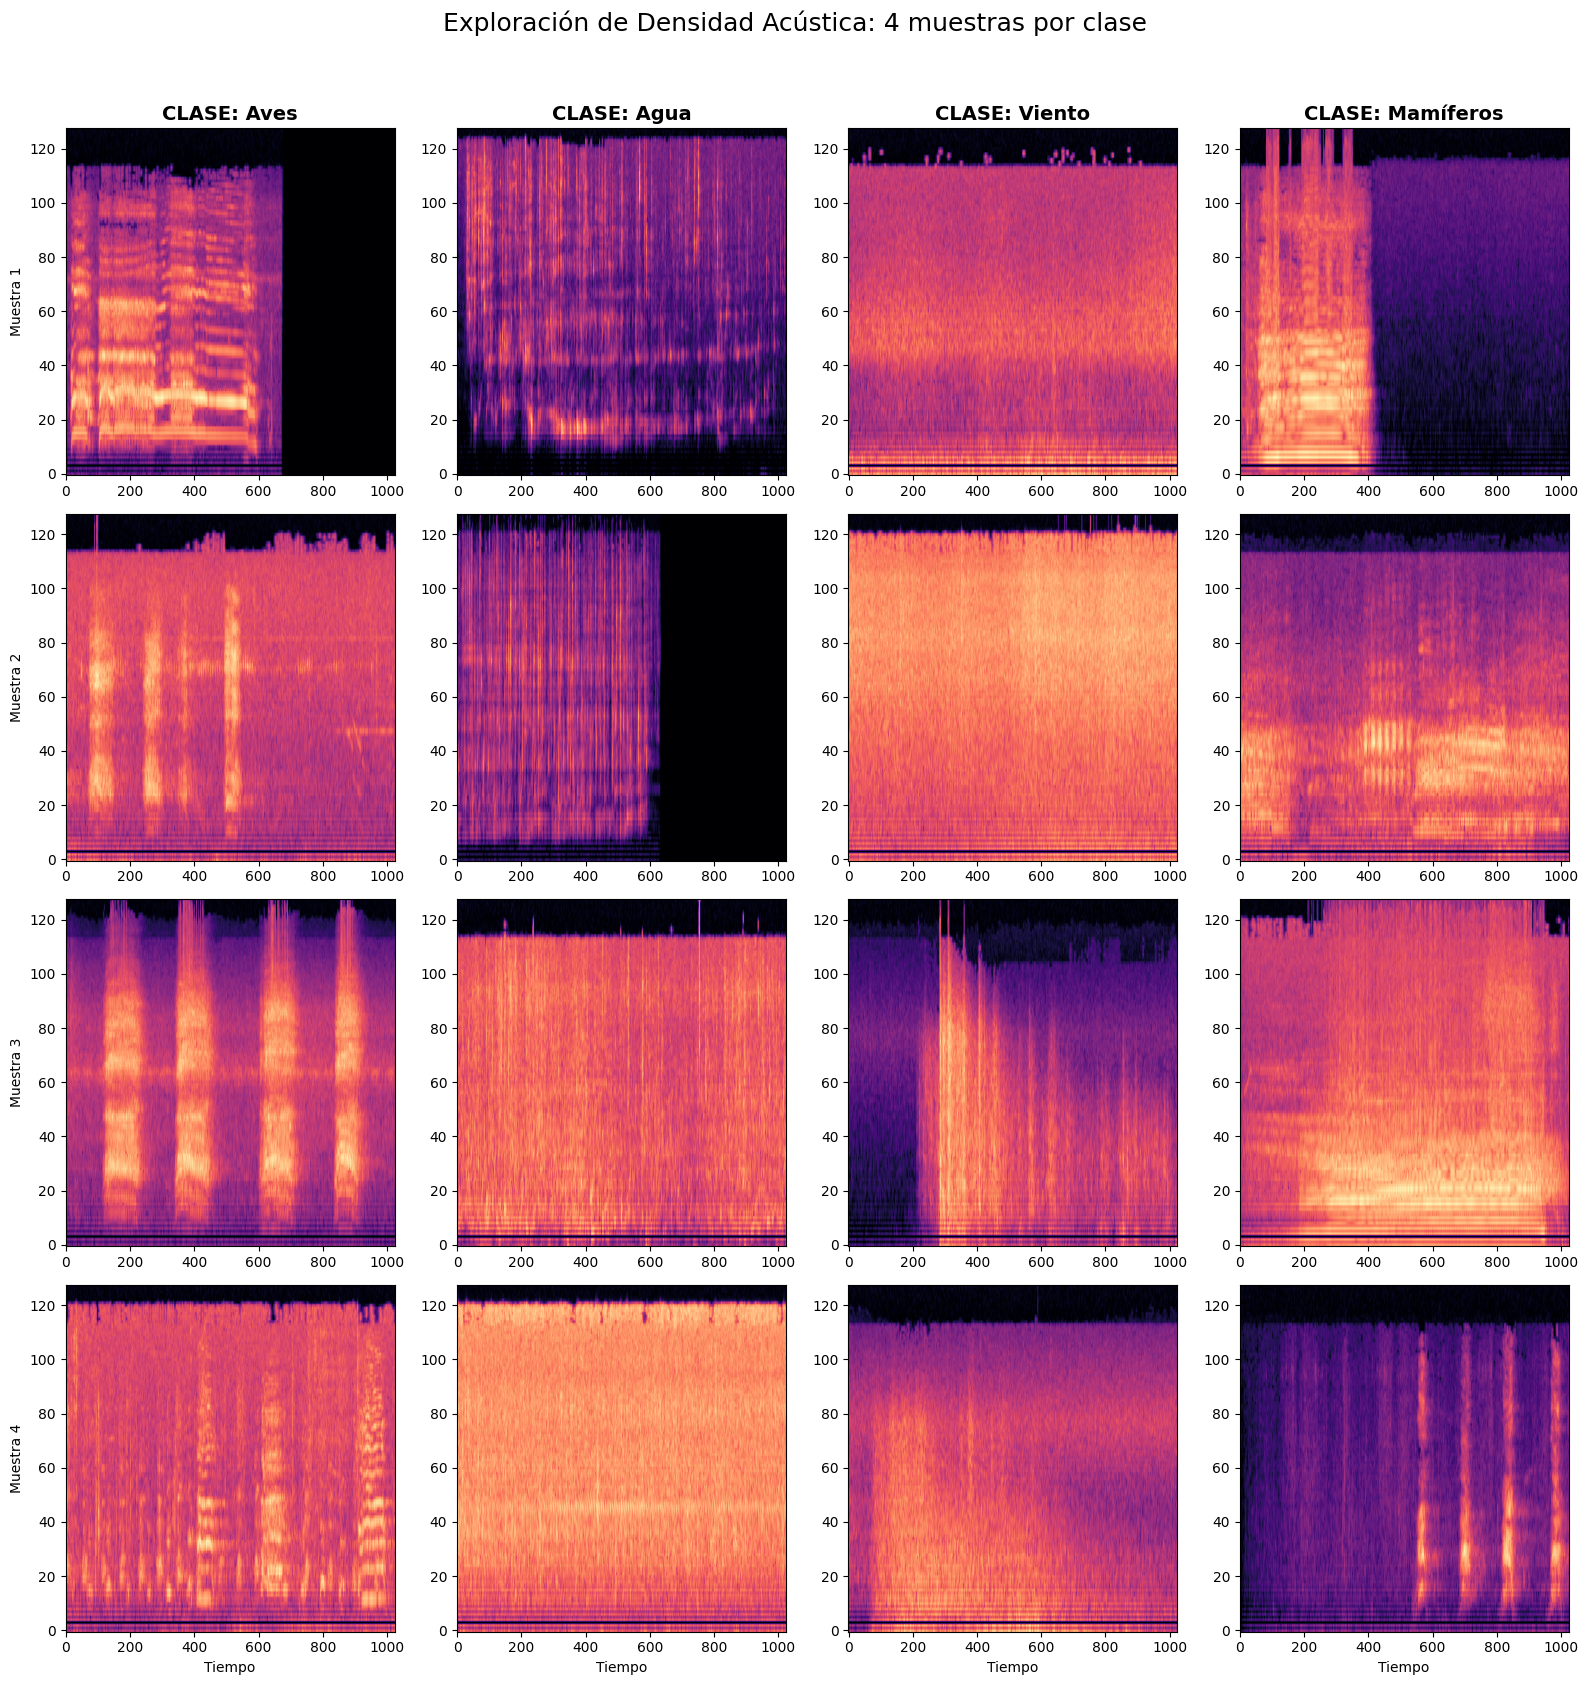

In [29]:
visualizar_muestras_grid(encoded_val, target_names, muestras_por_clase=4)

- En la figura anterior se aprecia que el eje x corresponde a la escala temporal y el eje y a la frecuencia en bandas de Mel
- También hay partes en negro en algunas imágenes, esto se debe a la estandarización de los 10s de duración de cada muestra que tiene configurado el AST. Se espera que el modelo logre ignorar estos espacios y se enfoque en la dinámica del movmiento de los sonidos representados en los espectrogramas

___
### 5. Configuración e implementación del modelo

Se utilizará el modelo MIT/ast-finetuned-audioset-10-10-0.4593. Como este modelo fue entrenado originalmente para 527 clases, se debe sustituir su capa final por una cabeza de clasificación de 4 neuronas (num_labels)

Para abordar el desbalance de clases identificado en la fase de exploración ($n=64$ para "Viento" frente a $n=160$ para "Mamíferos"), se implementará una estrategia de Aprendizaje Sensible al Costo (Cost-Sensitive Learning). 

Esta técnica es fundamental en Deep Learning cuando se dispone de un número limitado de épocas, ya que permite que el gradiente de la función de pérdida asigne mayor importancia a las muestras de la clase minoritaria durante el proceso de optimización. 

Debido a que el modelo Audio Spectrogram Transformer (AST) utiliza mecanismos de auto-atención para evaluar todas las relaciones entre los elementos de una secuencia, un desbalance no compensado podría sesgar la atención hacia patrones acústicos de las clases más frecuentes.  

- Se seleccionó el F1-Score como métrica principal debido a su capacidad para evaluar el desempeño del modelo de manera equilibrada frente al desbalance de clases detectado en el dataset. Al representar una medida entre Precisión y el Recall, esta métrica garantiza que el modelo no solo sea exacto en términos generales, sino también sea efectivo en identificar correctamente cada categoría, penalizando tanto los falsos positivos como los falsos negativos

In [17]:
# Cálculo de pesos inversamente proporcionales a la frecuencia de las clases
# Basado en el balance: Aves(128), Agua(128), Viento(64), Mamíferos(160)

# Pesos: Aves(1.0), Agua(1.0), Viento(2.0), Mamíferos(0.8)
class_weights = torch.tensor([1.0, 1.0, 2.0, 0.8], dtype=torch.float32).to(device)
weighted_loss_fct = nn.CrossEntropyLoss(weight=class_weights)

# 2. Mapeos y Métricas
label2id = {name: i for i, name in enumerate(target_names)}
id2label = {i: name for i, name in enumerate(target_names)}
metric = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels, average="macro")

# Minimiza la creación de tensores en cada paso
class RobustWeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        
        # Aplicación de la pérdida pre-calculada
        loss = weighted_loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

# Carga del Modelo
model = ASTForAudioClassification.from_pretrained(
    "MIT/ast-finetuned-audioset-10-10-0.4593",
    num_labels=4,
    label2id=label2id,
    id2label=id2label,
    ignore_mismatched_sizes=True).to(device)

# Congelar Parámetros
# Congelamos todo y luego abrimos selectivamente el final
for param in model.parameters():
    param.requires_grad = False

# Abrimos 'la cabeza', la normalización y el último bloque del Transformer (layer 11)
for name, param in model.named_parameters():
    if "classifier" in name or "layernorm" in name or "encoder.layer.11" in name:
        param.requires_grad = True
    

# 3. Configuración del entrenamiento
training_args = TrainingArguments(
    output_dir="./results_ast_nature",
    num_train_epochs=5,
    per_device_train_batch_size=4,   # Para evitar saturación del Kernel
    per_device_eval_batch_size=4,   
    eval_strategy="epoch",
    save_strategy="epoch",
    lr_scheduler_type="cosine",      # Ayuda a bajar suavemente
    learning_rate=2e-5,
    logging_steps=5,                # Reportar más seguido para ver progreso
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    dataloader_pin_memory=False,     # Obligatorio para MPS
    dataloader_num_workers=0,        # Evita conflictos de hilos en macOS
    fp16=False,                      # Usar precisión completa para evitar nan/crashes en MPS
    report_to="none"
)


# 4. Inicialización de Trainer
trainer = RobustWeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=encoded_train,
    eval_dataset=encoded_val,
    compute_metrics=compute_metrics
)

print(f"Entrenamiento iniciado en: {device}. .")
trainer.train()


[transformers] You passed `num_labels=4` which is incompatible to the `id2label` map of length `527`.


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

[transformers] ASTForAudioClassification LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                     | Status   |                                                                                         
------------------------+----------+-----------------------------------------------------------------------------------------
classifier.dense.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527, 768]) vs model:torch.Size([4, 768])
classifier.dense.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([527]) vs model:torch.Size([4])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Entrenamiento iniciado en: mps. .


Epoch,Training Loss,Validation Loss,F1
1,0.641413,0.915500,0.689324
2,0.461797,0.722882,0.694130
3,0.519960,0.669681,0.772579
4,0.378728,0.642050,0.818787
5,0.319798,0.640114,0.818787


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=600, training_loss=0.610136058529218, metrics={'train_runtime': 556.3259, 'train_samples_per_second': 4.314, 'train_steps_per_second': 1.079, 'total_flos': 1.626817186234368e+17, 'train_loss': 0.610136058529218, 'epoch': 5.0})

### 6. ANÁLISIS DE RESULTADOS

#### 6.1 GRÁFICA DE PÉRDIDA ENTRENAMIENTO vs VALIDACIÓN

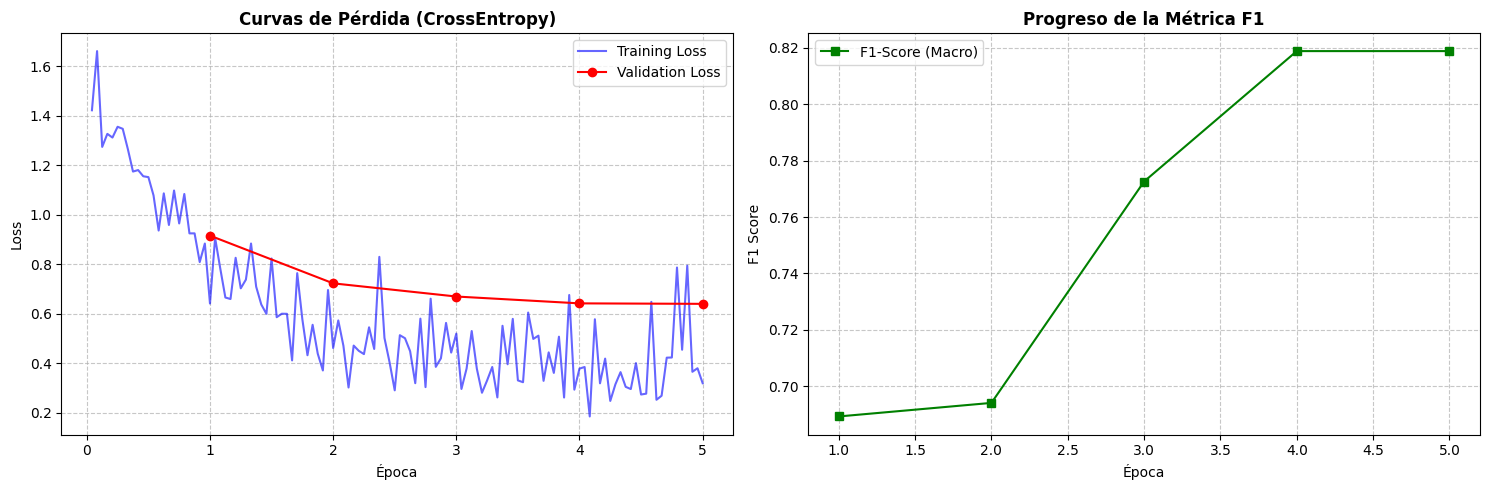

In [31]:
# Se extrae el historial de logs del trainer de Huggin Face
history = trainer.state.log_history

# Se convierte a un DataFrame de Pandas
df = pd.DataFrame(history)

# Se separan los logs de entrenamiento (que tienen 'loss') 
# de los de evaluación (que tienen 'eval_loss')
train_logs = df[df['loss'].notna()]
eval_logs = df[df['eval_loss'].notna()]

# Se crea la figura con dos subplots (Pérdida y F1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# --- Gráfica de Pérdida (Loss) ---
ax1.plot(train_logs['epoch'], train_logs['loss'], label='Training Loss', color='blue', alpha=0.6)
ax1.plot(eval_logs['epoch'], eval_logs['eval_loss'], label='Validation Loss', color='red', marker='o')
ax1.set_title('Curvas de Pérdida (CrossEntropy)', fontweight='bold')
ax1.set_xlabel('Época')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.7)

# --- Gráfica de F1-Score ---
ax2.plot(eval_logs['epoch'], eval_logs['eval_f1'], label='F1-Score (Macro)', color='green', marker='s')
ax2.set_title('Progreso de la Métrica F1', fontweight='bold')
ax2.set_xlabel('Época')
ax2.set_ylabel('F1 Score')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

Se aprecia que con 2 épocas no es suficiente para obtener un modelo que sea considerableente bueno. A partir de la época 4, la métrica F1 score se estabiliza y se observa que el training loss continúa bajando a pesar de que el validation loss se mantenga estable, lo que podría significar que el modelo dejaría de aprender y empieza a memorizar los datos de entrenamiento

#### 6.1 MATRIZ DE CONFUSIÓN

Reporte de Clasificación:
              precision    recall  f1-score   support

        Aves       0.76      0.88      0.81        32
        Agua       0.83      0.91      0.87        32
      Viento       0.91      0.62      0.74        16
   Mamíferos       0.89      0.82      0.86        40

    accuracy                           0.83       120
   macro avg       0.85      0.81      0.82       120
weighted avg       0.84      0.83      0.83       120



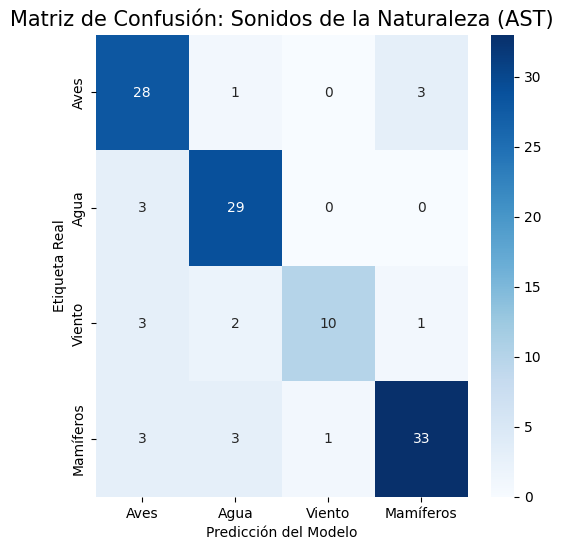

In [36]:
# Se obbtienen las predicciones sobre el set de validación (n=120)
predictions = trainer.predict(encoded_val)
y_pred = np.argmax(predictions.predictions, axis=-1)
y_true = predictions.label_ids

# Generar el reporte de métricas
report = classification_report(y_true, y_pred, target_names=target_names)
print("Reporte de Clasificación:")
print(report)

# Visualización de la Matriz de Confusión
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Matriz de Confusión: Sonidos de la Naturaleza (AST)', fontsize=15)
plt.xlabel('Predicción del Modelo')
plt.ylabel('Etiqueta Real')
plt.show()

### 7. CONCLUSIONES

- Con un Macro F1-score de 0.82, se puede concluir que el modelo no solo es bueno prediciendo la clase mayoritaria (Mamíferos), sino que ha aprendido características distintivas de todas las categorías. La pequeña diferencia entre el Macro Avg (0.82) y el Weighted Avg (0.83) indica que el modelo es consistente y no presenta un sesgo marcado hacia ninguna clase a pesar del ligero desbalance en el número de muestras.
- La categoría Agua es la mejor clasificada con un F1 de 0.87. Su alto Recall (0.91) demuestra que el modelo identifica casi la totalidad de los sonidos de agua presentes.
- Para la categoría de Agua, cuando el modelo predice que es "Viento", tiene un 91% de certeza. Casi nunca se equivoca al etiquetarlo. Sin embargo, se le escapan muchos sonidos de viento (los confunde con otros) lo que explica un Recall de 0.62
- El modelo AST alcanzó una convergencia óptima con una exactitud global del 83%. El análisis por clase revela que el Agua y los Mamíferos son los más fáciles de generalizar para la arquitectura. El desafío principal reside en la discriminación del Viento, donde el modelo prioriza la precisión sobre la sensibilidad para evitar solapamientos acústicos con el ruido ambiente
- La Matriz de Confusión presenta una diagonal marcada, lo que significa que el modelo no está adivinando y cuenta con una base sólida para clasificar los sonidos
- El modelo demuestra su mayor eficacia en la clase Mamíferos, logrando clasificar correctamente el 82.5% de sus muestras, lo que valida la técnica de fine-tuning incluso con mayor volumen de datos
- La matriz confirma que el Viento es la clase con mayor ambigüedad. La confusión repartida entre Aves y Agua sugiere que el modelo necesita más muestras de viento con diferentes intensidades para aprender a separarlo del ruido ambiental de fondo

### Referencias Bibliográficas

[1] Y. Gong, Y. A. Chung, and J. Glass, "AST: Audio Spectrogram Transformer," Proc. Interspeech 2021, pp. 571–575, 2021.

[2] K. J. Piczak, "ESC: Dataset for Environmental Sound Classification," Proceedings of the 23rd ACM international conference on Multimedia, pp. 1015–1018, 2015.

[3] T. Wolf et al., "Transformers: State-of-the-Art Natural Language Processing," Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing: System Demonstrations, pp. 38–45, 2020.

[4] Hugging Face Documentation, "Audio Spectrogram Transformer (AST) Feature Extractor," transformers library, 2024.